# Which errors the correctness model makes, and whether guessing explains them

The headline model predicts whether a participant picked the correct answer, at about 0.83 balanced accuracy. It gets two kinds of thing wrong, in very unequal numbers: false negatives (the person was right, the model said wrong) outnumber false positives by about eight to one. Nothing in the training favours one kind of error over the other, so that comes from the data. Note that "positive" here means the participant got it right, not that the model fired. This notebook shows the four cases behind that, for each of the three held-out test regimes, and then asks whether lucky guessing accounts for the imbalance.

Guessing comes into it because the label may be wrong. If what the model reads is how sure someone was rather than whether they were right, then a person who did not know the answer but picked it anyway is still scored correct, and a model that called them wrong is counted as making an error when it arguably read them right. Working out how many of the false negatives are lucky guesses needs two assumptions Study 1 cannot test: that everyone who answered wrong did not know the answer, and that every non-knower has the same chance `p` of guessing right. So `p` is tried at a half, a third and a quarter rather than fixed, and the lucky guesses are placed two different ways to give bounds rather than one number. Study 2's no-knowledge regime is where `p` gets measured instead of assumed. Until then everything in the second half of this notebook depends on those assumptions.

All of it comes from held-out predictions, never training ones, using the same folds and the same twelve features as the headline model. These are its mistakes, not a different model's.

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "__init__.py").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.lib.plotting.output import set_output_defaults
set_output_defaults(save=False)   # this notebook only shows; it saves nothing

import time

import matplotlib.pyplot as plt

from src.config.datasets import dataset
from src.features.build import load_model_input
from src.analyses.error_analysis import compute as EC
from src.analyses.error_analysis import plots as EP

# One row per word; each trial's values repeat on every word. The cross-validation
# needs it to resolve folds; the trial table it scores is loaded inside.
all_participants = load_model_input(dataset("l1"))

  grains: interest_areas (760628, 23), areas_answers (97180, 19), trials (19436, 89)


## 1. The held-out predictions
*`compute.py`*

One logistic regression trained across everyone, cross-validated on the pooled folds, giving one row per held-out trial, fold and regime. The twelve features are the headline model's ten attention measures plus the two last-fixation ones, which is also what the per-person models use, so the two sets of mistakes can be compared.

Six regimes come back: three `val_*` and three `test_*`. Only the three test regimes are used below. They differ in what is new to the model -- the item, the reader, or both -- and each pools only the trials that match it, so their counts differ several-fold.

The run takes a minute or two.

In [2]:
t0 = time.perf_counter()
preds = EC.run_crossval_predictions(all_participants, verbose=False)
print(f"{len(preds):,} held-out predictions in {time.perf_counter() - t0:.0f} s")
print()
print("features:", *EC.default_feature_cols(), sep="\n  ")
print()
preds.groupby("regime").size().rename("n_predictions").to_frame()

69,968 held-out predictions in 16 s

features:
  area_dwell_proportion__correct
  area_dwell_proportion__question
  skip_rate__correct
  has_xyx
  ANSWER_PRESS_NUMBER
  num_label_visits__correct
  num_label_visits__contrast
  mean_fixations_count__question
  mean_fixations_count__wrong_mean
  mean_max_fix_pupil_size_z__correct
  last_before_confirm_correct
  last_before_confirm_question



,n_predictions
regime,
test_seen_subject_unseen_item,15548
test_unseen_subject_seen_item,15548
test_unseen_subject_unseen_item,5832
val_seen_subject_unseen_item,15548
val_unseen_subject_seen_item,15548
val_unseen_subject_unseen_item,1944


## 2. What the errors are
*`compute.build_trial_prediction_table`, `plots.plot_confusion_quadrants`*

Each held-out trial falls into one of four cases. "Correct" always means the participant was right, never the model:

|                   | model says correct | model says wrong |
|-------------------|--------------------|------------------|
| **human correct** | TP                 | FN               |
| **human wrong**   | FP                 | TN               |

The regime below is the strict one: a reader the model has not seen, on an item it has not seen. The split printed at the end is what this whole analysis is about.

5832 pooled held-out trials
  TP - true positive       3936  ( 67.5%)
  TN - true negative        799  ( 13.7%)
  FP - false positive       124  (  2.1%)
  FN - false negative       973  ( 16.7%)
  Errors: 1097 total  |  FP 11.3%  |  FN 88.7%


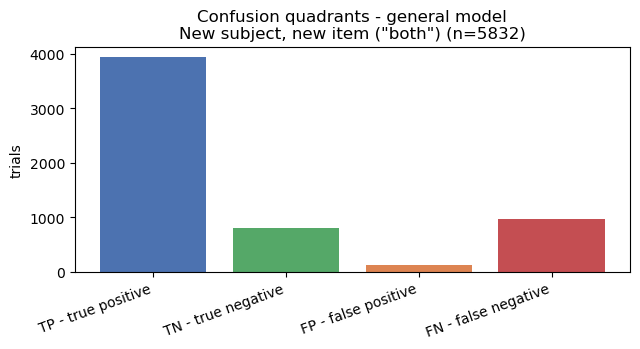

In [3]:
REGIME = EP.HEADLINE_REGIME   # 'test_unseen_subject_unseen_item'

trials = EC.build_trial_prediction_table(preds, REGIME)
counts = EC.confusion_summary(trials, verbose=True)

fig, _ = EP.plot_confusion_quadrants(trials, regime=REGIME, save=False)
plt.show()

### The same four numbers as a matrix
*`plots.plot_confusion_matrix`*

Rows are what the participant did, columns what the model said, so the diagonal is the model getting it right. The colour shows the row share rather than the count: four in five answers are correct, so on a raw scale the three smaller cells come out the same shade. Both numbers are in every cell either way. By row, the top is sensitivity and the bottom is specificity.

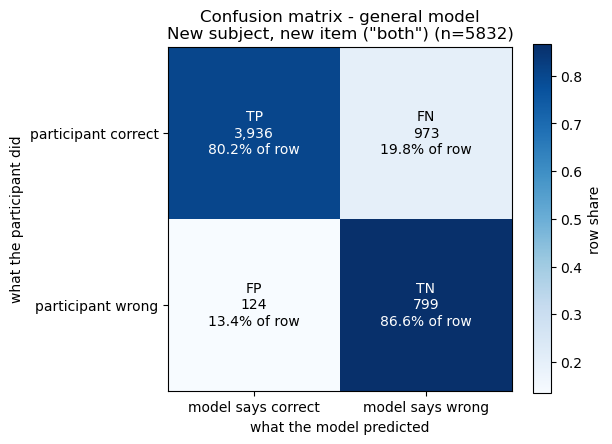

,model says correct,model says wrong
participant correct,0.802,0.198
participant wrong,0.134,0.866


In [4]:
fig, matrix = EP.plot_confusion_matrix(trials, regime=REGIME, save=False)
plt.show()
matrix.round(3)

## 3. The same breakdown for every test regime
*`compute.quadrants_by_regime`, `plots.plot_confusion_quadrants_by_regime`*

The y-axes are independent on purpose. Each regime pools only its own trials, so the counts differ several-fold and one axis would flatten two panels to nothing. Compare the shapes, not the heights. The table below has the shares, which do compare.

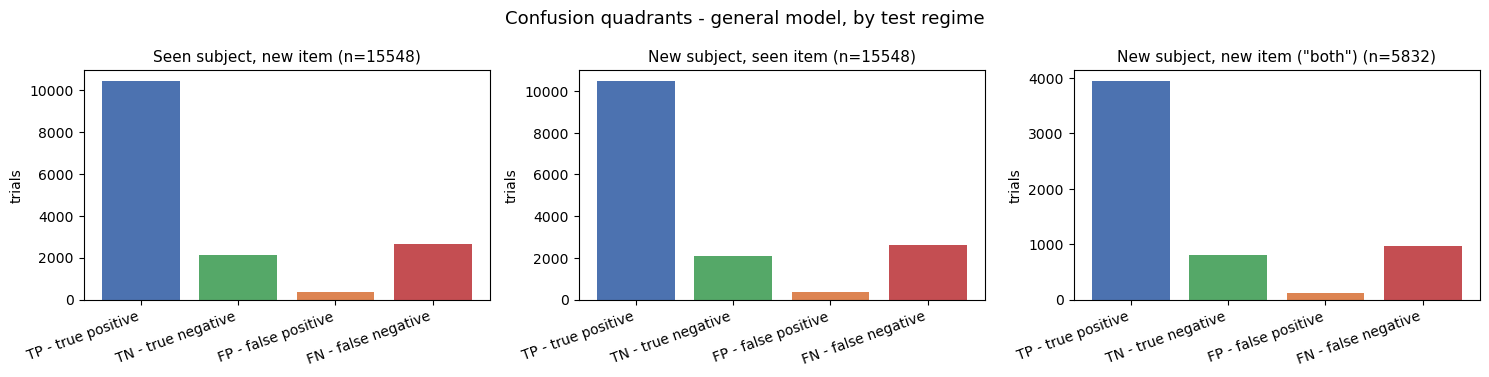

quadrant,FN,FP,TN,TP
regime_title,,,,
"New subject, new item (""both"")",0.167,0.021,0.137,0.675
"New subject, seen item",0.169,0.022,0.136,0.673
"Seen subject, new item",0.171,0.022,0.138,0.669


In [5]:
fig, by_regime = EP.plot_confusion_quadrants_by_regime(preds, save=False)
plt.show()
by_regime.pivot(index="regime_title", columns="quadrant", values="share").round(3)

## 4. Does guessing explain the imbalance?
*`compute.guess_adjust`, `compute.guessing_scenarios`*

Assume everyone who answered wrong did not know the answer, and that every non-knower has the same chance `p` of guessing right. The wrong answers then count the non-knowers who guessed badly, and the ones who guessed well -- invisible, scored as correct -- number `n_wrong * p / (1 - p)`.

Where those lucky guesses sit among the correct answers is unknown, so two bounds are worked out. Under **`excuse_false_negatives`** the model spots every non-knower, so every lucky guess is one it called wrong and each moves FN to TN; this is the reading kindest to the model. Under **`proportional`** the model cannot tell them apart, so the lucky guesses split between TP and FN by size, which turns some TP into FP as well. The answer is between the two.

Watch the FN/FP ratio against its raw value: if it drops towards 1, guessing accounts for the imbalance. `n_lucky_applied` and `clamped` say whether there was room to place the estimate. A clamped row means that at that `p` the guessing story needs more lucky guesses than the data holds, which says something about `p` rather than being a number to read past.

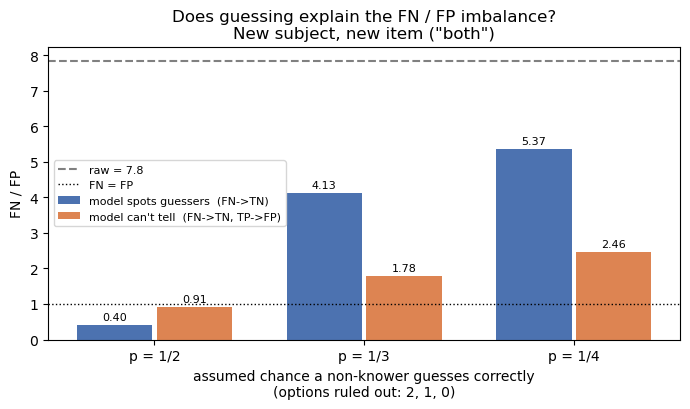

,scenario,mode,p,FP,FN,FN/FP,n_lucky,n_lucky_applied,clamped,n_trials
0,raw,-,NaN,124.000,973.000,7.847,0.000,0.000,False,5832
1,guess 1/2,excuse_false_negatives,0.500,124.000,50.000,0.403,923.000,923.000,False,5832
2,guess 1/2,proportional,0.500,864.055,790.055,0.914,923.000,923.000,False,5832
3,guess 1/3,excuse_false_negatives,0.333,124.000,511.500,4.125,461.500,461.500,False,5832
4,guess 1/3,proportional,0.333,494.027,881.527,1.784,461.500,461.500,False,5832
5,guess 1/4,excuse_false_negatives,0.250,124.000,665.333,5.366,307.667,307.667,False,5832
6,guess 1/4,proportional,0.250,370.685,912.018,2.460,307.667,307.667,False,5832


In [6]:
fig, scenarios = EP.plot_guessing_scenarios(counts, regime=REGIME, save=False)
plt.show()
scenarios.drop(columns=["regime"]).round(3)

## 5. The correction across all three regimes
*`compute.guessing_scenarios_by_regime`, `plots.plot_guessing_scenarios_by_regime`*

Here the y-axis is shared, unlike the panels above: a ratio has no units, so comparing regimes is the question. The dashed line in each panel is that regime's raw ratio, the dotted line is where FN and FP would be equal.

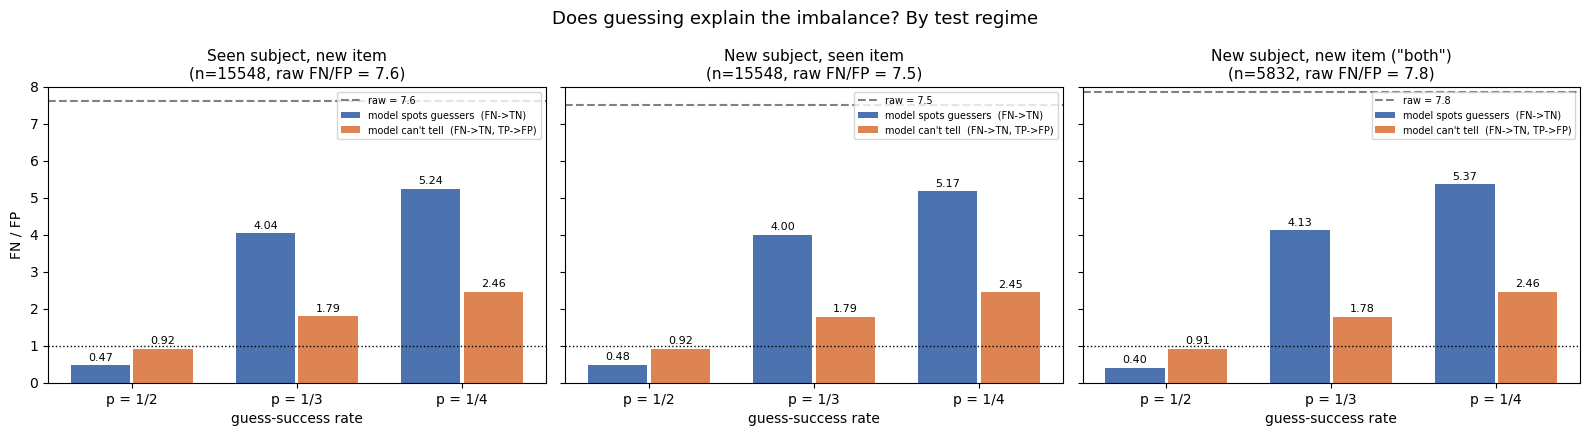

scenario                                                guess 1/2  guess 1/3  \
regime                          mode                                           
test_seen_subject_unseen_item   excuse_false_negatives       0.47       4.04   
                                proportional                 0.92       1.79   
test_unseen_subject_seen_item   excuse_false_negatives       0.48       4.00   
                                proportional                 0.92       1.79   
test_unseen_subject_unseen_item excuse_false_negatives       0.40       4.13   
                                proportional                 0.91       1.78   

scenario                                                guess 1/4  
regime                          mode                               
test_seen_subject_unseen_item   excuse_false_negatives       5.24  
                                proportional                 2.46  
test_unseen_subject_seen_item   excuse_false_negatives       5.17  
                                proportional                 2.45  
test_unseen_subject_unseen_item excuse_false_negatives       5.37  
                                proportional                 2.46

In [7]:
fig, by_regime_scenarios = EP.plot_guessing_scenarios_by_regime(preds, save=False)
plt.show()
by_regime_scenarios[by_regime_scenarios["mode"] != "-"].pivot_table(
    index=["regime", "mode"], columns="scenario", values="FN/FP"
).round(2)

## 6. Where the errors balance
*`compute.balance_point`, `plots.plot_guessing_balance`*

Every lucky guess takes one trial out of the human-correct row. If the model had called it wrong it goes FN to TN, so FN drops by one; if the model had called it right it goes TP to FP, so FP rises by one. Either way the gap `FN - FP` shrinks by exactly one:

    FN' - FP' = (FN - FP) - n_lucky

The split does not appear. So the errors balance as soon as `n_lucky` reaches the gap, at `p* = gap / (gap + n_wrong)`, whatever the split happens to be.

That is worth more than it first looks. The split is the part we cannot observe, and it has no bearing on where the ratio crosses 1 -- only on how far the ratio travels on the way. In the figure the band closes to a single point, exactly on the FN = FP line.

Reading it: the errors balance at about p = 0.48, which is a non-knower landing on the right answer roughly half the time -- someone who had it down to two options. Pure chance across four options is 0.25 and eliminating one is 0.33, so both of those leave a large imbalance standing. Study 2's no-knowledge regime is what settles which is realistic.

In the strip on the right the estimate wants to move more trials than there are false negatives, so `excuse_false_negatives` runs out and the band stops meaning what it means to the left of it.

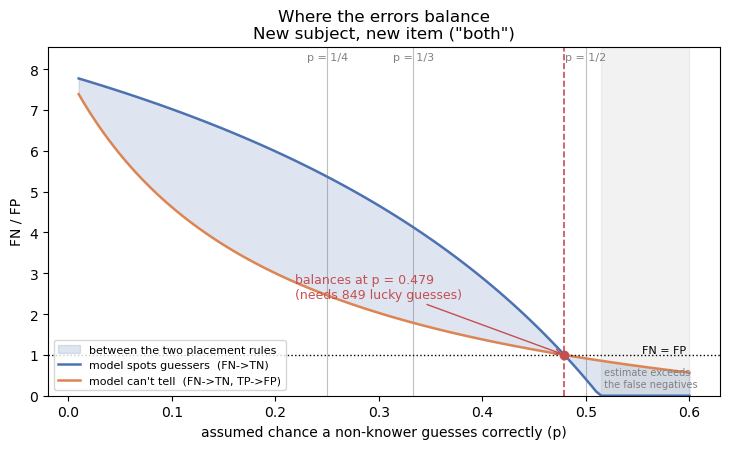

,regime,gap_fn_minus_fp,n_wrong,n_lucky_needed,p_star
0,"Seen subject, new item",2304.0,2489.0,2304.0,0.481
1,"New subject, seen item",2275.0,2457.0,2275.0,0.481
2,"New subject, new item (""both"")",849.0,923.0,849.0,0.479


In [8]:
fig, curve = EP.plot_guessing_balance(counts, regime=REGIME, save=False)
plt.show()

import pandas as pd
pd.DataFrame([
    dict(regime=EC.REGIME_TITLES[r],
         **EC.balance_point(EC.confusion_counts(EC.build_trial_prediction_table(preds, r))))
    for r in EC.TEST_REGIMES
]).round(3)

`run_error_analysis` draws all of these in one call, for the headline regime and for the three test regimes side by side. `python scripts/run_analysis.py --name error_analysis` runs it and saves the figures and the numbers behind them under `reports/error_analysis/`; the cross-validation runs once inside the script, which is the slowest part of it.

The per-participant version of this is `src/analyses/correctness_prediction/person_variance/overview.ipynb`, which asks the same thing of one model per participant instead of one across everyone. The case names, ordering and colours are shared between them in `src/modeling/confusion.py`, so the two sets of figures can be read against each other.